# 02 · A budget in milliseconds

Nobody thinks in frames. `BudgetedSampler` takes a latency budget in milliseconds and nothing else: it fits a
small cost model on your machine (a few clips, a few configurations, cached afterwards), then for each video
picks the most accurate configuration whose predicted cost fits and re-plans once after the keyframe scan.

Needs: `pip install vam-runtime[hf] matplotlib`; a folder of long clips (`CLIPS` below; THUMOS14 validation
videos by default). The accuracy ordering it uses was measured on THUMOS14 (`docs/results/thumos14_scheduler.md`).

In [1]:
import glob
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

import vam

CLIPS = sorted(glob.glob(os.environ.get("VAM_CLIPS", "data/thumos14/videos/video_validation_*.mp4")))[:20]
device = "cuda" if torch.cuda.is_available() else "cpu"
model = vam.get_model("videomae-base-kinetics", device=device)
print(f"{len(CLIPS)} clips, {device}")

/home/vrishabh/Documents/Coding/vivaan/vam/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 186/186 [00:00<00:00, 13585.15it/s]

20 clips, cuda


## Calibrate once
Three clips × four configurations × two repeats, after a discarded warm-up pass. The fitted model is
`intercept + per-keyframe + per-window-frame + per-refinement-candidate + per-model-frame` with a p75 residual
kept as a safety margin. It is cached per machine in `~/.cache/vam/`; `cache=False` here so the notebook
always shows the fit.

In [2]:
t0 = time.time()
sampler = vam.BudgetedSampler(150, model, calibrate_on=CLIPS[:3], cache=False)
cm = sampler.cost
print(f"calibrated in {time.time() - t0:.1f} s on {cm.n_fit} timings")
print(f"intercept {cm.w[0]:.0f} ms · per keyframe {cm.w[1]:.2f} · per window frame {cm.w[2]:.2f} · "
      f"per candidate {cm.w[3]:.2f} · per model frame {cm.w[4]:.2f} · refinement {cm.w[5]:.0f} · margin (p75) {cm.resid_p75:.0f} ms")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 85800.42it/s]

calibrated in 6.1 s on 24 timings
intercept 63 ms · per keyframe 0.00 · per window frame 0.42 · per candidate 0.17 · per model frame 0.11 · refinement 0 · margin (p75) 19 ms


## Sweep budgets
The same clips under 100, 150, 200 and 300 ms. For each video: what the scheduler chose, what it predicted,
what it actually cost.

In [3]:
budgets = [100, 150, 200, 300]
rows = []
for b in budgets:
    sampler = vam.BudgetedSampler(b, model, cost=cm)
    for clip in CLIPS[3:]:
        v = vam.load_video(clip)
        t0 = time.perf_counter()
        model(v, sampler=sampler)
        if device == "cuda":
            torch.cuda.synchronize()
        ms = (time.perf_counter() - t0) * 1000
        plan = sampler.last_plan
        rows.append({"budget": b, "clip": os.path.basename(clip), "config": str(plan.config), "predicted": plan.predicted_ms,
                     "measured": ms, "stage": plan.stage, "fallback": sampler.last.last_fallback})
        v.close()
    chosen = {}
    for r in rows:
        if r["budget"] == b:
            chosen[r["config"]] = chosen.get(r["config"], 0) + 1
    meas = np.array([r["measured"] for r in rows if r["budget"] == b])
    print(f"budget {b:3d} ms: p50 {np.median(meas):4.0f}  p90 {np.percentile(meas, 90):4.0f}  within {np.mean(meas <= b):.2f}  chose {chosen}")

budget 100 ms: p50  101  p90  167  within 0.41  chose {'4f': 17}


budget 150 ms: p50  110  p90  180  within 0.76  chose {'16f': 17}


budget 200 ms: p50  133  p90  203  within 0.88  chose {'16f+refine/3': 17}


budget 300 ms: p50  130  p90  202  within 1.00  chose {'16f+refine/3': 17}


## Predicted vs measured
Points near the diagonal mean the cost model knows this machine. The spread above it is host jitter: on a shared
machine the 90th percentile sits 50–60 ms above the median whatever the policy, so a budget is a median promise.

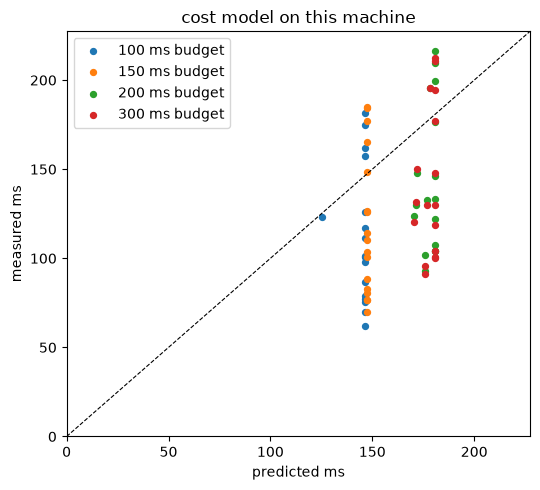

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for b in budgets:
    rs = [r for r in rows if r["budget"] == b]
    ax.scatter([r["predicted"] for r in rs], [r["measured"] for r in rs], s=18, label=f"{b} ms budget")
lim = max(r["measured"] for r in rows) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=0.8)
ax.set_xlabel("predicted ms")
ax.set_ylabel("measured ms")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.legend()
ax.set_title("cost model on this machine")
plt.tight_layout()
plt.show()

## What the budget buys
On an RTX 5090 with 200 THUMOS14 videos (`docs/results/thumos14_scheduler.md`):

| budget | chosen | top-1 | uniform at any of these budgets |
|---|---|---|---|
| 100 ms | 4 frames | 0.855 | 0.720 |
| 150 ms | 8 frames, some 16 | 0.960 | 0.720 |
| 200 ms | 16 frames + refinement, stride 3 | 0.945 | 0.720 |

The curve walks the accuracy–latency frontier by itself; on a CPU-only host it makes different choices at
every budget because its cost model is fitted there. When the scan carries no information (one keyframe,
flat scores, windows that would cover most of the clip) it answers with uniform frames, which is the right
call on footage like Charades where the action fills the clip (`docs/results/charades.md`).

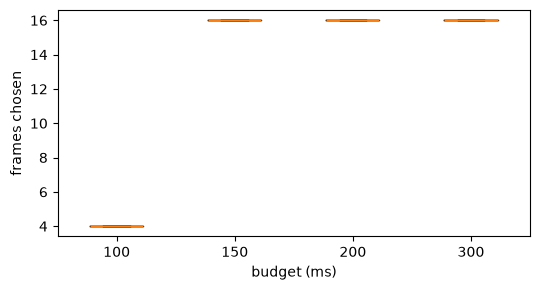

In [5]:
frames = {b: [int(r["config"].split("f")[0].replace("uniform-", "")) for r in rows if r["budget"] == b] for b in budgets}
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.boxplot([frames[b] for b in budgets])
ax.set_xticks(range(1, len(budgets) + 1), [str(b) for b in budgets])
ax.set_xlabel("budget (ms)")
ax.set_ylabel("frames chosen")
plt.tight_layout()
plt.show()

In [6]:
vam.runtime.shutdown_pools()